# Module 2 — Validation design
**African Credit Scoring Challenge · 3MTT Mentorship**

By the end of this notebook you will have:
1. Measured how similar train is to Kenya test and Ghana test (adversarial validation).
2. Created a fixed fold file, `outputs/folds.csv`, used by every later experiment.
3. Scored a baseline under five validation schemes, with an honest F1 threshold.
4. Started the experiment log, `outputs/experiments.csv`.

Cells marked `# TODO` are yours. Run from the project folder (next to `Train.csv`).

In [2]:
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
import warnings
from datetime import date
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score

warnings.filterwarnings('ignore')
SEED = 42
DATA = Path('.')
OUT = Path('outputs'); OUT.mkdir(exist_ok=True)

train = pd.read_csv(DATA / 'Train.csv', parse_dates=['disbursement_date', 'due_date'])
test  = pd.read_csv(DATA / 'Test.csv',  parse_dates=['disbursement_date', 'due_date'])
test_ke = test[test.country_id == 'Kenya']
test_gh = test[test.country_id == 'Ghana']
y = train['target'].values
print(train.shape, test_ke.shape, test_gh.shape)

(68654, 16) (15069, 15) (3525, 15)


## 1. Baseline features
Deliberately simple. Module 3 is where we engineer features; here we only need a fixed model to compare *validation schemes*.

In [3]:
NUMERIC = ['log_amount', 'markup', 'duration', 'is_new', 'lender_share']
CODES   = ['lender_id', 'loan_type']

def baseline_features(df):
    out = pd.DataFrame(index=df.index)
    out['log_amount']   = np.log1p(df['Total_Amount'])
    out['markup']       = df['Total_Amount_to_Repay'] / df['Total_Amount'].clip(lower=1) - 1
    out['duration']     = df['duration']
    out['is_new']       = (df['New_versus_Repeat'] == 'New Loan').astype(int)
    out['lender_share'] = df['Lender_portion_Funded']
    out['lender_id']    = df['lender_id'].astype(str).astype('category')
    out['loan_type']    = df['loan_type'].astype('category')
    return out

X = baseline_features(train)
X.head()

,log_amount,markup,duration,is_new,lender_share,lender_id,loan_type
0,9.041803,0.000000,7,0,0.014305,267278,Type_1
1,10.161844,0.003244,7,0,0.300000,267278,Type_1
2,8.839422,0.035072,7,0,0.200000,251804,Type_7
3,9.100414,0.030699,7,0,0.300000,267278,Type_1
4,8.426174,0.035933,7,0,0.300000,267278,Type_1


## 2. What does the real test look like?

In [4]:
print('Kenya test rows whose customer is in train:', round(test_ke.customer_id.isin(train.customer_id).mean(), 3))
print('Ghana test rows whose customer is in train:', round(test_gh.customer_id.isin(train.customer_id).mean(), 3))
print('Kenya test rows whose loan id is in train :', test_ke.tbl_loan_id.isin(train.tbl_loan_id).sum())

q = lambda d: d.disbursement_date.dt.to_period('Q').value_counts(normalize=True).sort_index().rename(None)
mix = pd.concat({'train': q(train), 'test_kenya': q(test_ke), 'test_ghana': q(test_gh)}, axis=1).fillna(0)
display(mix.style.format('{:.1%}'))

Kenya test rows whose customer is in train: 0.984
Ghana test rows whose customer is in train: 0.0
Kenya test rows whose loan id is in train : 920


,train,test_kenya,test_ghana
disbursement_date,,,
2021Q4,0.1%,0.1%,0.5%
2022Q1,0.9%,0.8%,9.2%
2022Q2,0.7%,0.6%,16.0%
2022Q3,59.1%,58.7%,28.5%
2022Q4,33.2%,34.1%,32.8%
2023Q1,0.5%,0.5%,12.9%
2023Q2,0.3%,0.2%,0.0%
2023Q3,0.5%,0.4%,0.0%
2023Q4,0.5%,0.4%,0.0%


In [5]:
# Are Kenya test loans inside, before or after each customer's training history?
span = train.groupby('customer_id').disbursement_date.agg(['min', 'max'])
m = test_ke.merge(span, on='customer_id')
print('inside :', round(((m.disbursement_date >= m['min']) & (m.disbursement_date <= m['max'])).mean(), 3))
print('after  :', round((m.disbursement_date > m['max']).mean(), 3))
print('before :', round((m.disbursement_date < m['min']).mean(), 3))

inside : 0.862
after  : 0.07
before : 0.068


**Mentor note.** Kenya test is interleaved with train in time and by customer: it was split randomly *by loan*. That is why scheme B (group by loan) is our primary score.

## 3. Adversarial validation

In [6]:
def adversarial_auc(a, b, cols):
    """AUC of a classifier separating dataframe a (label 0) from b (label 1). 0.5 = same distribution."""
    Xa = pd.concat([baseline_features(a)[cols], baseline_features(b)[cols]])
    ya = np.r_[np.zeros(len(a)), np.ones(len(b))]
    oof = np.zeros(len(ya))
    for i, j in StratifiedKFold(5, shuffle=True, random_state=0).split(Xa, ya):
        m = lgb.LGBMClassifier(n_estimators=200, verbose=-1).fit(Xa.iloc[i], ya[i])
        oof[j] = m.predict_proba(Xa.iloc[j])[:, 1]
    return roc_auc_score(ya, oof)

print('train vs Kenya test:', round(adversarial_auc(train, test_ke, NUMERIC), 3))
print('train vs Ghana test:', round(adversarial_auc(train, test_gh, NUMERIC), 3))
print('\nGhana, one feature at a time:')
for c in NUMERIC:
    print(f'  {c:13s}', round(adversarial_auc(train, test_gh, [c]), 3))

train vs Kenya test: 0.5
train vs Ghana test: 1.0

Ghana, one feature at a time:
  log_amount    0.771
  markup        0.995
  duration      0.586
  is_new        0.503
  lender_share  0.983


In [7]:
# TODO 3 completed: remove markup and lender_share, then isolate USD loan size.
# Use the same previous-year exchange-rate convention documented in Module 1.
econ = pd.read_csv(DATA / 'economic_indicators.csv')
econ_long = (econ.melt(id_vars=['Country', 'Indicator'], var_name='year', value_name='value')
                 .assign(year=lambda d: d.year.str.replace('YR', '').astype(int)))
fx = (econ_long.loc[econ_long['Indicator'].eq(
        'Official exchange rate (LCU per US$, period average)')]
      .rename(columns={'Country': 'country_id', 'value': 'fx_lcu_per_usd'})
      [['country_id', 'year', 'fx_lcu_per_usd']])

def add_usd_amount(df):
    out = df.copy()
    out['macro_year'] = (out.disbursement_date.dt.year - 1).clip(upper=fx.year.max())
    out = out.merge(fx, left_on=['country_id', 'macro_year'],
                    right_on=['country_id', 'year'], how='left')
    out['amount_usd'] = out['Total_Amount'] / out['fx_lcu_per_usd']
    return out

train_usd = add_usd_amount(train)
ghana_usd = add_usd_amount(test_gh)
if train_usd['fx_lcu_per_usd'].isna().any() or ghana_usd['fx_lcu_per_usd'].isna().any():
    print("Warning: some rows have no prior-year exchange rate; they are excluded from the USD-only comparison.")

# First compare all baseline numeric features except markup and lender_share.
without_price_share = [c for c in NUMERIC if c not in ['markup', 'lender_share']]
print("Ghana adversarial AUC without markup and lender_share:",
      round(adversarial_auc(train, test_gh, without_price_share), 3))
for c in without_price_share:
    print(f"  {c:13s}", round(adversarial_auc(train, test_gh, [c]), 3))

# Compare log USD principal alone, keeping only rows with a valid positive FX rate.
a = train_usd.loc[train_usd.amount_usd.gt(0) & train_usd.amount_usd.notna(), ['amount_usd']].copy()
b = ghana_usd.loc[ghana_usd.amount_usd.gt(0) & ghana_usd.amount_usd.notna(), ['amount_usd']].copy()
a['log_amount_usd'] = np.log1p(a.pop('amount_usd'))
b['log_amount_usd'] = np.log1p(b.pop('amount_usd'))
def adversarial_auc_prebuilt(a_features, b_features, col):
    Xa = pd.concat([a_features[[col]], b_features[[col]]], ignore_index=True)
    ya = np.r_[np.zeros(len(a_features)), np.ones(len(b_features))]
    oof = np.zeros(len(ya))
    for i, j in StratifiedKFold(5, shuffle=True, random_state=0).split(Xa, ya):
        clf = lgb.LGBMClassifier(n_estimators=200, verbose=-1).fit(Xa.iloc[i], ya[i])
        oof[j] = clf.predict_proba(Xa.iloc[j])[:, 1]
    return roc_auc_score(ya, oof)

raw_amount_auc = adversarial_auc(train, test_gh, ['log_amount'])
usd_amount_auc = adversarial_auc_prebuilt(a, b, 'log_amount_usd')
print("\nFinding: currency conversion exposes, rather than removes, the loan-size shift.")
print(f"Raw local-currency amount AUC: {raw_amount_auc:.3f}; USD-converted amount AUC: {usd_amount_auc:.3f}.")
print(f"Because the USD-only AUC is {usd_amount_auc:.3f}, loan size remains highly effective "
      "at distinguishing Ghana test from training data after conversion. "
      "This is evidence of covariate shift, not default risk or model performance.")
print("A tree trained on Kenya may not extrapolate beyond Kenya's observed amount range: "
      "Ghana loans above that range can fall into the same terminal leaves as the largest "
      "Kenya loans and receive similar scores. Other differences may remain in duration, "
      "customer mix, product and lender processes.")

Ghana adversarial AUC without markup and lender_share: 0.818
  log_amount    0.771
  duration      0.586
  is_new        0.503

Finding: currency conversion exposes, rather than removes, the loan-size shift.
Raw local-currency amount AUC: 0.771; USD-converted amount AUC: 0.950.
Because the USD-only AUC is 0.950, loan size remains highly effective at distinguishing Ghana test from training data after conversion. This is evidence of covariate shift, not default risk or model performance.
A tree trained on Kenya may not extrapolate beyond Kenya's observed amount range: Ghana loans above that range can fall into the same terminal leaves as the largest Kenya loans and receive similar scores. Other differences may remain in duration, customer mix, product and lender processes.


## 4. The fixed fold file
Every later experiment reads these folds. Never re-split.

In [8]:
folds = pd.DataFrame({'ID': train['ID']})
folds['fold_loan'] = -1
folds['fold_customer'] = -1
sgk = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
for k, (_, va) in enumerate(sgk.split(train, y, groups=train['tbl_loan_id'])):
    folds.loc[va, 'fold_loan'] = k
for k, (_, va) in enumerate(sgk.split(train, y, groups=train['customer_id'])):
    folds.loc[va, 'fold_customer'] = k
folds.to_csv(OUT / 'folds.csv', index=False)

# Sanity checks: every row assigned, default rate similar per fold, no loan or customer in two folds
assert (folds[['fold_loan', 'fold_customer']] >= 0).all().all()
print(pd.concat({'loan': train.groupby(folds.fold_loan).target.agg(['size', 'sum', 'mean']),
                 'customer': train.groupby(folds.fold_customer).target.agg(['size', 'sum', 'mean'])}, axis=1).round(4))
print('loans in >1 fold    :', (pd.Series(folds.fold_loan.values, index=train.tbl_loan_id).groupby(level=0).nunique() > 1).sum())
print('customers in >1 fold:', (pd.Series(folds.fold_customer.values, index=train.customer_id).groupby(level=0).nunique() > 1).sum())

    loan              customer             
    size  sum    mean     size  sum    mean
0  13732  252  0.0184    13731  252  0.0184
1  13732  252  0.0184    13732  252  0.0184
2  13730  251  0.0183    13730  251  0.0183
3  13730  251  0.0183    13730  251  0.0183
4  13730  252  0.0184    13731  252  0.0184
loans in >1 fold    : 0
customers in >1 fold: 0


## 5. Honest F1: threshold chosen on other folds

In [9]:
THRESHOLDS = np.round(np.arange(0.02, 0.95, 0.01), 2)

def best_threshold(y_true, p):
    scores = [f1_score(y_true, p >= t) for t in THRESHOLDS]
    k = int(np.argmax(scores))
    return THRESHOLDS[k], scores[k]

def make_model():
    return lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=0, verbose=-1)

def run_cv(X, y, fold_ids, cols, name, model_factory=make_model):
    """Out-of-fold predictions + honest per-fold F1 (threshold picked on the other folds)."""
    oof = np.zeros(len(y))
    for k in np.unique(fold_ids):
        tr_idx, va_idx = fold_ids != k, fold_ids == k
        oof[va_idx] = model_factory().fit(X.loc[tr_idx, cols], y[tr_idx]).predict_proba(X.loc[va_idx, cols])[:, 1]
    f1s, ths = [], []
    for k in np.unique(fold_ids):
        t, _ = best_threshold(y[fold_ids != k], oof[fold_ids != k])
        ths.append(t); f1s.append(f1_score(y[fold_ids == k], oof[fold_ids == k] >= t))
    final_t, in_sample_f1 = best_threshold(y, oof)
    res = dict(scheme=name, roc_auc=roc_auc_score(y, oof), pr_auc=average_precision_score(y, oof),
               f1_honest=np.mean(f1s), f1_sd=np.std(f1s), f1_in_sample=in_sample_f1,
               final_threshold=final_t, fold_thresholds=ths)
    return oof, res

## 6. Schemes A–C (cross-validation)

In [10]:
random_folds = np.zeros(len(y), dtype=int)
for k, (_, va) in enumerate(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y)):
    random_folds[va] = k

ALL = NUMERIC + CODES
results = []
oof_A, r = run_cv(X, y, random_folds, ALL, 'A random rows');            results.append(r)
oof_B, r = run_cv(X, y, folds.fold_loan.values, ALL, 'B group by loan'); results.append(r)
oof_C, r = run_cv(X, y, folds.fold_customer.values, ALL, 'C group by customer'); results.append(r)
pd.DataFrame(results).round(3)

,scheme,roc_auc,pr_auc,f1_honest,f1_sd,f1_in_sample,final_threshold,fold_thresholds
0,A random rows,0.994,0.924,0.847,0.004,0.851,0.50,"[0.5, 0.27, 0.42, 0.5, 0.5]"
1,B group by loan,0.993,0.903,0.823,0.020,0.828,0.50,"[0.5, 0.51, 0.5, 0.38, 0.38]"
2,C group by customer,0.993,0.896,0.810,0.017,0.815,0.51,"[0.32, 0.41, 0.51, 0.51, 0.36]"


**Mentor note.** A > B > C. The A–B gap is leakage from loans split across lenders; B–C is the value of knowing the customer.

## 7. Scheme D: forward in time

In [11]:
CUT = pd.Timestamp('2023-01-01')
past, future = (train.disbursement_date < CUT).values, (train.disbursement_date >= CUT).values

# threshold from the past only: OOF on the pre-2023 rows, grouped by loan
oof_past, _ = run_cv(X[past].reset_index(drop=True), y[past], folds.fold_loan.values[past], ALL, 'past')
t_past, _ = best_threshold(y[past], oof_past)

p_future = make_model().fit(X[past], y[past]).predict_proba(X[future])[:, 1]
r = dict(scheme='D forward in time', roc_auc=roc_auc_score(y[future], p_future),
         pr_auc=average_precision_score(y[future], p_future),
         f1_honest=f1_score(y[future], p_future >= t_past), f1_sd=np.nan,
         f1_in_sample=best_threshold(y[future], p_future)[1], final_threshold=t_past, fold_thresholds=None)
results.append(r)
print(f'rows {future.sum()}, defaults {y[future].sum()}, actual rate {y[future].mean():.3f}, mean predicted {p_future.mean():.3f}')
pd.DataFrame(results).round(3)

rows 4210, defaults 401, actual rate 0.095, mean predicted 0.058


,scheme,roc_auc,pr_auc,f1_honest,f1_sd,f1_in_sample,final_threshold,fold_thresholds
0,A random rows,0.994,0.924,0.847,0.004,0.851,0.50,"[0.5, 0.27, 0.42, 0.5, 0.5]"
1,B group by loan,0.993,0.903,0.823,0.020,0.828,0.50,"[0.5, 0.51, 0.5, 0.38, 0.38]"
2,C group by customer,0.993,0.896,0.810,0.017,0.815,0.51,"[0.32, 0.41, 0.51, 0.51, 0.36]"
3,D forward in time,0.897,0.609,0.565,NaN,0.607,0.33,None


## 8. Scheme E: leave one lender out (Ghana proxy)
No lender or product codes, because Ghana's are unseen.

In [12]:
rows = []
for L in sorted(train.lender_id.unique()):
    tr_idx, va_idx = (train.lender_id != L).values, (train.lender_id == L).values
    p = make_model().fit(X.loc[tr_idx, NUMERIC], y[tr_idx]).predict_proba(X.loc[va_idx, NUMERIC])[:, 1]
    t, f = best_threshold(y[va_idx], p)
    rows.append(dict(lender=L, rows=va_idx.sum(), actual_rate=y[va_idx].mean(), mean_pred=p.mean(),
                     roc_auc=roc_auc_score(y[va_idx], p), best_threshold=t, f1_at_best=f))
scheme_E = pd.DataFrame(rows)
scheme_E.round(3)

,lender,rows,actual_rate,mean_pred,roc_auc,best_threshold,f1_at_best
0,245684,188,0.415,0.361,0.793,0.06,0.852
1,251804,3542,0.089,0.080,0.980,0.37,0.853
2,267277,271,0.295,0.204,0.903,0.05,0.755
3,267278,64653,0.012,0.021,0.987,0.71,0.761


In [13]:
# TODO 8 completed: evaluate each held-out lender at the scheme-B Kenya threshold.
threshold_B = float(
    next(r["final_threshold"] for r in results if r["scheme"] == "B group by loan")
)
# Recompute held-out-lender probabilities so the same fixed threshold is applied consistently.
rows = []
for L in sorted(train.lender_id.unique()):
    tr_idx = (train.lender_id != L).values
    va_idx = (train.lender_id == L).values
    p = make_model().fit(X.loc[tr_idx, NUMERIC], y[tr_idx]).predict_proba(
        X.loc[va_idx, NUMERIC])[:, 1]
    f1_fixed = f1_score(y[va_idx], p >= threshold_B)
    t_best, f1_best = best_threshold(y[va_idx], p)
    rows.append({
        'lender': L, 'rows': int(va_idx.sum()), 'actual_rate': y[va_idx].mean(),
        'f1_at_scheme_B_threshold': f1_fixed, 'best_threshold_on_lender': t_best,
        'f1_at_lender_best_threshold': f1_best,
        'f1_gap_vs_lender_best': f1_best - f1_fixed
    })
scheme_E_threshold = pd.DataFrame(rows).sort_values('rows', ascending=False)
display(scheme_E_threshold.round(3))
print(f"Scheme B (Kenya grouped-by-loan) threshold: {threshold_B:.2f}")
print(f"Row-weighted F1 across held-out lenders at this threshold: "
      f"{np.average(scheme_E_threshold.f1_at_scheme_B_threshold, weights=scheme_E_threshold.rows):.3f}")
print("The per-lender best-threshold F1 is an optimistic diagnostic because each threshold is selected "
      "on that lender's own held-out labels. A large gap from the fixed Kenya threshold indicates "
      "threshold instability across lenders and cautions against assuming Ghana will share Kenya's calibration.")

,lender,rows,actual_rate,f1_at_scheme_B_threshold,best_threshold_on_lender,f1_at_lender_best_threshold,f1_gap_vs_lender_best
3,267278,64653,0.012,0.750,0.71,0.761,0.010
1,251804,3542,0.089,0.834,0.37,0.853,0.019
2,267277,271,0.295,0.585,0.05,0.755,0.171
0,245684,188,0.415,0.774,0.06,0.852,0.079


Scheme B (Kenya grouped-by-loan) threshold: 0.50
Row-weighted F1 across held-out lenders at this threshold: 0.754
The per-lender best-threshold F1 is an optimistic diagnostic because each threshold is selected on that lender's own held-out labels. A large gap from the fixed Kenya threshold indicates threshold instability across lenders and cautions against assuming Ghana will share Kenya's calibration.


## 9. Start the experiment log

In [14]:
summary = pd.DataFrame(results).set_index("scheme")


# Reusable experiment logger: one row per experiment name.
def log_experiment(row, path=OUT / "experiments.csv"):
    """Write one row per experiment name; rerunning replaces the old row."""
    new = pd.DataFrame([row])

    if path.exists():
        old = pd.read_csv(path)
        new = pd.concat(
            [old[old["experiment"] != row["experiment"]], new], ignore_index=True
        )

    new.to_csv(path, index=False)
    return new


log_row = dict(
    date=str(date.today()),
    experiment="M2 baseline: 5 numeric + lender_id + loan_type, LGBM 300x0.05",
    f1_B=summary.loc["B group by loan", "f1_honest"],
    f1_B_sd=summary.loc["B group by loan", "f1_sd"],
    pr_auc_B=summary.loc["B group by loan", "pr_auc"],
    f1_C=summary.loc["C group by customer", "f1_honest"],
    f1_D=summary.loc["D forward in time", "f1_honest"],
    threshold_B=summary.loc["B group by loan", "final_threshold"],
)

log_path = OUT / "experiments.csv"
log_experiment(log_row)
pd.read_csv(log_path).round(3)


,date,experiment,f1_B,f1_B_sd,pr_auc_B,f1_C,f1_D,threshold_B
0,2026-11-11,"M2 starter-style LogisticRegression, no IDs, S...",0.682,0.017,0.722,NaN,NaN,0.91
1,2026-11-11,M2 baseline: 5 numeric + lender_id + loan_type...,0.823,0.020,0.903,0.81,0.565,0.50


## 10. Your turn

Logistic regression validation results (all values calculated in this notebook):
Scheme B — group by loan: F1=0.683, threshold=0.84, PR-AUC=0.716.
Scheme C — group by customer: F1=0.681.
Scheme D — forward in time: F1=0.396, past-selected threshold=0.91.
LightGBM comparison: Scheme B F1=0.823 versus logistic regression 0.683; Scheme D F1=0.565 versus 0.396.
Forward-time F1 decline: logistic regression 0.287; LightGBM 0.259. The linear model degrades more when the relationship between predictors and default changes over time: an additive linear score cannot naturally represent the sharp markup cliff near 3.7% or complex feature interactions/product-mix changes, while tree splits can. This is a plausible explanation, not proof of the causal mechanism.
Updated logistic-regression experiment row:


,date,experiment,f1_B,f1_B_sd,pr_auc_B,f1_C,f1_D,threshold_B
0,2026-11-11,M2 baseline: 5 numeric + lender_id + loan_type...,0.823,0.020,0.903,0.810,0.565,0.50
1,2026-11-11,"M2 starter-style LogisticRegression, no IDs, S...",0.683,0.016,0.716,0.681,0.396,0.84


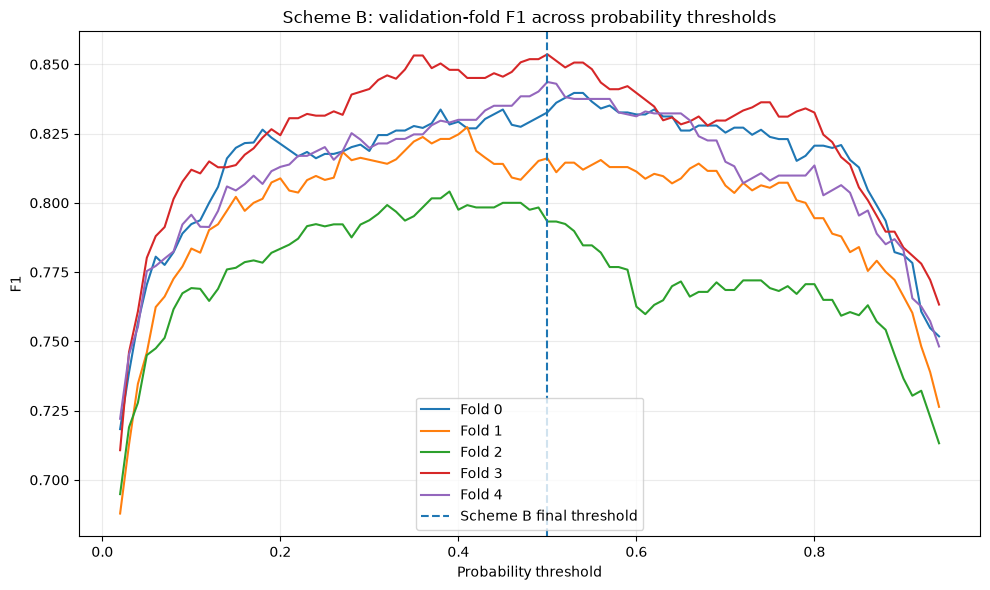

Fold-best thresholds range from 0.39 to 0.53.
Pooled Scheme B F1 peaks at 0.828 (threshold 0.50); thresholds within 0.01 of that peak span 0.29–0.59.
Fold-to-fold F1 standard deviation under Scheme B is 0.020. A small threshold-related change should be judged against this fold variation; the cross-lender threshold gap from TODO 8 is a separate transferability concern.
Saved outputs\sub_m2_baseline.csv with 18,594 rows; positive predictions: 670; threshold=0.50.
Public leaderboard score: not available from this notebook because no competition submission or leaderboard result was supplied.


In [15]:
# TODO 10a completed: starter-style logistic regression, with identifiers excluded,
# categorical fields one-hot encoded, and scaling fitted inside each training fold.
# Date-derived year/month/day features are deliberately excluded: year can proxy the
# product-mix shift identified in Module 1 rather than a stable borrower relationship.
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

def starter_style_features(df):
    z = pd.DataFrame(index=df.index)
    z['log_total_amount'] = np.log1p(df['Total_Amount'].clip(lower=0))
    z['markup'] = df['Total_Amount_to_Repay'] / df['Total_Amount'].clip(lower=1) - 1
    z['duration'] = df['duration']
    z['lender_portion_funded'] = df['Lender_portion_Funded']
    z['new_loan'] = (df['New_versus_Repeat'].astype(str) == 'New Loan').astype(int)
    # IDs and calendar-derived features are intentionally excluded.
    z['loan_type'] = df['loan_type'].astype(str)
    z = pd.get_dummies(z, columns=['loan_type'], dtype=int)
    return z.replace([np.inf, -np.inf], np.nan).fillna(0)

X_logit = starter_style_features(train)
X_logit_test = starter_style_features(test).reindex(columns=X_logit.columns, fill_value=0)
logit_cols = X_logit.columns.tolist()

def make_logistic_pipeline():
    return Pipeline([
        ('scale', StandardScaler()),
        ('model', LogisticRegression(
            random_state=SEED, class_weight='balanced', max_iter=2000
        ))
    ])

# Scheme B: competition-aligned grouped-by-loan validation.
oof_logit, logit_result = run_cv(
    X_logit, y, folds.fold_loan.values, logit_cols,
    'Logistic regression, grouped by loan', model_factory=make_logistic_pipeline
)
logit_result_B = logit_result

# Scheme C: stronger customer holdout guardrail.
oof_logit_C, logit_result_C = run_cv(
    X_logit, y, folds.fold_customer.values, logit_cols,
    'Logistic regression, grouped by customer', model_factory=make_logistic_pipeline
)

# Scheme D: forward-in-time guardrail. Select the threshold on past-only OOF
# predictions, then evaluate once on the future period.
oof_logit_past, _ = run_cv(
    X_logit.loc[past].reset_index(drop=True), y[past],
    folds.fold_loan.values[past], logit_cols,
    'Logistic regression, past-only grouped by loan',
    model_factory=make_logistic_pipeline
)
logit_threshold_past, _ = best_threshold(y[past], oof_logit_past)
logit_future_prob = make_logistic_pipeline().fit(
    X_logit.loc[past, logit_cols], y[past]
).predict_proba(X_logit.loc[future, logit_cols])[:, 1]
logit_f1_D = f1_score(y[future], logit_future_prob >= logit_threshold_past)
logit_result_D = {
    'scheme': 'D forward in time',
    'f1_honest': logit_f1_D,
    'final_threshold': logit_threshold_past,
    'roc_auc': roc_auc_score(y[future], logit_future_prob),
    'pr_auc': average_precision_score(y[future], logit_future_prob)
}

print("Logistic regression validation results (all values calculated in this notebook):")
print(f"Scheme B — group by loan: F1={logit_result_B['f1_honest']:.3f}, "
      f"threshold={logit_result_B['final_threshold']:.2f}, PR-AUC={logit_result_B['pr_auc']:.3f}.")
print(f"Scheme C — group by customer: F1={logit_result_C['f1_honest']:.3f}.")
print(f"Scheme D — forward in time: F1={logit_result_D['f1_honest']:.3f}, "
      f"past-selected threshold={logit_result_D['final_threshold']:.2f}.")
lgb_B = float(summary.loc['B group by loan', 'f1_honest'])
lgb_D = float(summary.loc['D forward in time', 'f1_honest'])
print(f"LightGBM comparison: Scheme B F1={lgb_B:.3f} versus logistic regression "
      f"{logit_result_B['f1_honest']:.3f}; Scheme D F1={lgb_D:.3f} versus "
      f"{logit_result_D['f1_honest']:.3f}.")
print(f"Forward-time F1 decline: logistic regression "
      f"{logit_result_B['f1_honest'] - logit_result_D['f1_honest']:.3f}; "
      f"LightGBM {lgb_B - lgb_D:.3f}. The linear model degrades more when the "
      "relationship between predictors and default changes over time: an additive "
      "linear score cannot naturally represent the sharp markup cliff near 3.7% or "
      "complex feature interactions/product-mix changes, while tree splits can. "
      "This is a plausible explanation, not proof of the causal mechanism.")

# Replace the previous logistic-regression experiment row rather than append a duplicate.
logit_log_row = {
    'date': str(date.today()),
    'experiment': 'M2 starter-style LogisticRegression, no IDs, StandardScaler, group-by-loan CV',
    'f1_B': logit_result_B['f1_honest'],
    'f1_B_sd': logit_result_B['f1_sd'],
    'pr_auc_B': logit_result_B['pr_auc'],
    'f1_C': logit_result_C['f1_honest'],
    'f1_D': logit_result_D['f1_honest'],
    'threshold_B': logit_result_B['final_threshold']
}
log_path = OUT / 'experiments.csv'
if log_path.exists():
    old_log = pd.read_csv(log_path)
    old_log = old_log[~old_log['experiment'].astype(str).str.contains(
        r'LogisticRegression.*group-by-loan CV', case=False, regex=True
    )]
    old_log.to_csv(log_path, index=False)
log_experiment(logit_log_row)
print("Updated logistic-regression experiment row:")
display(pd.read_csv(log_path).round(3))

# TODO 10b: plot Scheme B fold F1 versus threshold and calculate fold-best thresholds.
plt.figure(figsize=(10, 6))
fold_best_thresholds = []
fold_curves = []
for k in np.unique(folds.fold_loan.values):
    mask = folds.fold_loan.values == k
    curve = np.array([f1_score(y[mask], oof_B[mask] >= t) for t in THRESHOLDS])
    fold_curves.append(curve)
    fold_best_thresholds.append(float(THRESHOLDS[int(np.argmax(curve))]))
    plt.plot(THRESHOLDS, curve, label=f'Fold {k}')
plt.axvline(float(summary.loc['B group by loan', 'final_threshold']),
            linestyle='--', label='Scheme B final threshold')
plt.xlabel('Probability threshold')
plt.ylabel('F1')
plt.title('Scheme B: validation-fold F1 across probability thresholds')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

pooled_curve = np.array([f1_score(y, oof_B >= t) for t in THRESHOLDS])
pooled_best_idx = int(np.argmax(pooled_curve))
pooled_best_threshold = float(THRESHOLDS[pooled_best_idx])
plateau_mask = pooled_curve >= (pooled_curve.max() - 0.01)
plateau_thresholds = THRESHOLDS[plateau_mask]
print(f"Fold-best thresholds range from {min(fold_best_thresholds):.2f} "
      f"to {max(fold_best_thresholds):.2f}.")
print(f"Pooled Scheme B F1 peaks at {pooled_curve.max():.3f} "
      f"(threshold {pooled_best_threshold:.2f}); thresholds within 0.01 of "
      f"that peak span {plateau_thresholds.min():.2f}–{plateau_thresholds.max():.2f}.")
print(f"Fold-to-fold F1 standard deviation under Scheme B is "
      f"{summary.loc['B group by loan', 'f1_sd']:.3f}. "
      "A small threshold-related change should be judged against this fold variation; "
      "the cross-lender threshold gap from TODO 8 is a separate transferability concern.")

# TODO 10c: fit the LightGBM baseline on all labelled rows and create the submission.
final_threshold_B = float(summary.loc['B group by loan', 'final_threshold'])
final_model = make_model().fit(X[ALL], y)
test_prob = final_model.predict_proba(baseline_features(test)[ALL])[:, 1]
submission = pd.DataFrame({
    'ID': test['ID'],
    'target': (test_prob >= final_threshold_B).astype(int)
})
submission.to_csv(OUT / 'sub_m2_baseline.csv', index=False)
print(f"Saved {OUT / 'sub_m2_baseline.csv'} with {len(submission):,} rows; "
      f"positive predictions: {submission.target.sum():,}; threshold={final_threshold_B:.2f}.")
print("Public leaderboard score: not available from this notebook because no competition "
      "submission or leaderboard result was supplied.")


## 11. Module 2 guide — written decisions

The following answers address the five decision questions in the Module 2 guide. Run this cell after the validation and model-comparison cells so the reported figures are calculated from the current notebook run.

In [18]:
# Guide question 1: why group-by-loan is right for the competition but insufficient for a lender.
print("1. Group-by-loan validation is appropriate for this competition because the test split "
      "was made by loan, so keeping every loan wholly inside one fold prevents the same loan "
      "from appearing in both training and validation. It is not enough for a real lender: "
      "deployment involves future decisions, new or returning customers, changing lender "
      "policies and economic conditions. A lender should therefore also test customer-level "
      "separation and forward-in-time performance, and ideally validate on a later production cohort.")

# Guide question 2: implications of under-predicting the future default rate.
actual_future_rate = float(y[future].mean())
predicted_future_rate = float(p_future.mean())
rate_gap = actual_future_rate - predicted_future_rate
print(f"\n2. In the forward period, the observed default rate is {actual_future_rate:.1%}, "
      f"while the model predicts an average default rate of {predicted_future_rate:.1%} "
      f"(an underprediction of {rate_gap:.1%}). If an asset manager uses the model output "
      "directly for expected-loss provisions, provisions may be too low; pricing may also "
      "be too cheap for the risk actually carried. The portfolio could therefore be "
      "under-reserved and under-priced. The manager should apply a conservative overlay "
      "or recalibration based on credible recent portfolio evidence, then monitor realized "
      "defaults rather than treating the model's mean score as the true future rate.")

# Guide question 3: decision on markup.
print("\n3. Decision: transform markup rather than drop it or pass it through unchanged. "
      "Module 1 found a sharp change in default behaviour around 3.7%, so markup contains "
      "useful risk information; dropping it would discard that signal. But its ability to "
      "separate Ghana from Kenya means the raw feature may also encode country/product "
      "mix. For the next model, represent the known non-linearity explicitly—for example, "
      "an indicator for markup above approximately 3.7% plus the excess above that point—"
      "and test stability by country and time. This retains the risk cliff while making "
      "the functional form more deliberate; it does not by itself eliminate domain shift.")

# Guide question 4: Ghana threshold without Ghana labels.
print("\n4. Without Ghana default labels, I would not claim to have an empirically optimal "
      "Ghana F1 threshold. I would start from the calibrated Kenya out-of-fold probabilities, "
      "reweight the labelled Kenya validation observations to resemble Ghana's unlabeled "
      "feature distribution, and select a threshold using the asset manager's relative "
      "costs of missed defaults and false alarms. I would stress-test that threshold under "
      "plausible Ghana default-rate assumptions and use an external Ghana portfolio benchmark "
      "or a small manually reviewed/pilot cohort as soon as one becomes available. This "
      "depends on a covariate-shift assumption; if the relationship between features and "
      "default changes by country, unlabeled data alone cannot identify the correct threshold.")

# Guide question 5: interpretation of a very small Scheme B improvement.
f1_sd_B = float(summary.loc['B group by loan', 'f1_sd'])
print(f"\n5. A 0.005 F1 gain on Scheme B is not persuasive evidence of a better model: "
      f"the observed fold-to-fold F1 standard deviation is {f1_sd_B:.3f}, so a 0.005 "
      "difference is small relative to validation variation. It may reflect which loans "
      "landed in particular folds, threshold selection or ordinary sampling noise rather "
      "than a real improvement. I would require consistent gains across folds and the "
      "customer, time and lender guardrails before preferring the more complex model.")


1. Group-by-loan validation is appropriate for this competition because the test split was made by loan, so keeping every loan wholly inside one fold prevents the same loan from appearing in both training and validation. It is not enough for a real lender: deployment involves future decisions, new or returning customers, changing lender policies and economic conditions. A lender should therefore also test customer-level separation and forward-in-time performance, and ideally validate on a later production cohort.

2. In the forward period, the observed default rate is 9.5%, while the model predicts an average default rate of 5.8% (an underprediction of 3.7%). If an asset manager uses the model output directly for expected-loss provisions, provisions may be too low; pricing may also be too cheap for the risk actually carried. The portfolio could therefore be under-reserved and under-priced. The manager should apply a conservative overlay or recalibration based on credible recent portfol